In [1]:
from pathlib import Path

import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

DATA_PATH = ROOT / "data" / "processed" / "modeling_features.parquet"

assert DATA_PATH.exists(), "Day 4 Parquet file not found"

con = duckdb.connect()

df = con.execute(
    "SELECT * FROM read_parquet(?)",
    [str(DATA_PATH)]
).df()

print("Dataset shape:", df.shape)

display(df.head())

Dataset shape: (307511, 143)


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,bureau_total_overdue,bureau_max_credit,bureau_max_days_overdue,bureau_accounts_currently_overdue,bureau_avg_days_since_credit,bureau_days_since_recent_credit,bureau_days_since_oldest_credit,bureau_debt_records_available,bureau_credit_records_available,bureau_debt_credit_ratio
0,117276,0,Cash loans,F,N,Y,2,180000.0,363190.5,26559.0,...,0.0,6201.0,0,0,142.000000,42,242,2,2,0.000000
1,117277,1,Cash loans,F,N,Y,1,337500.0,732915.0,79065.0,...,0.0,1057500.0,0,0,1197.583333,140,1607,10,12,0.049512
2,117278,0,Cash loans,M,Y,Y,0,117000.0,112500.0,11254.5,...,NaN,NaN,<NA>,<NA>,NaN,<NA>,<NA>,<NA>,<NA>,NaN
3,117279,0,Cash loans,F,N,N,3,157500.0,1125000.0,47794.5,...,NaN,NaN,<NA>,<NA>,NaN,<NA>,<NA>,<NA>,<NA>,NaN
4,117280,0,Cash loans,F,N,Y,0,135000.0,450000.0,23107.5,...,0.0,585000.0,0,0,1238.571429,303,2714,5,7,0.413792


In [2]:
print(df["TARGET"].value_counts())
print(df["TARGET"].value_counts(normalize=True))

TARGET
0    282686
1     24825
Name: count, dtype: int64
TARGET
0    0.919271
1    0.080729
Name: proportion, dtype: float64


In [3]:
numeric_features = [
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "CNT_CHILDREN",
    "CNT_FAM_MEMBERS",
    "credit_income_ratio",
    "annuity_income_ratio",
    "employment_years",
    "employment_sentinel_flag",
    "EXT_SOURCE_1",
    "EXT_SOURCE_2",
    "EXT_SOURCE_3",
    "has_bureau_history",
    "bureau_total_accounts",
    "bureau_active_accounts",
    "bureau_closed_accounts",
    "bureau_total_credit",
    "bureau_total_debt",
    "bureau_total_overdue",
    "bureau_max_days_overdue",
    "bureau_avg_days_since_credit",
    "bureau_debt_credit_ratio",
]

categorical_features = [
    "NAME_INCOME_TYPE",
    "NAME_EDUCATION_TYPE",
    "NAME_HOUSING_TYPE",
    "FLAG_OWN_CAR",
    "FLAG_OWN_REALTY",
]

features = numeric_features + categorical_features

missing_columns = [
    col for col in features
    if col not in df.columns
]

assert not missing_columns, (
    f"Missing feature columns: {missing_columns}"
)

assert df["SK_ID_CURR"].is_unique
assert df["TARGET"].notna().all()
assert set(df["TARGET"].unique()) == {0, 1}

X = df[features].copy()
y = df["TARGET"].astype(int)

# Replace infinite numerical ratios with missing values.
X[numeric_features] = X[numeric_features].replace(
    [np.inf, -np.inf],
    np.nan
)

print("Features:", len(features))
print("Applications:", len(X))
print("Positive rate:", round(y.mean() * 100, 2), "%")

Features: 27
Applications: 307511
Positive rate: 8.07 %


In [4]:
from sklearn.model_selection import train_test_split

# Hold out 20% for final testing
X_dev, X_test, y_dev, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Split remaining 80% into 60% train and 20% validation
X_train, X_val, y_train, y_val = train_test_split(
    X_dev,
    y_dev,
    test_size=0.25,
    random_state=42,
    stratify=y_dev
)

for name, features_set, target_set in [
    ("Training", X_train, y_train),
    ("Validation", X_val, y_val),
    ("Test", X_test, y_test)
]:
    print(
        f"{name}: {len(features_set):,} applications | "
        f"Positive rate: {target_set.mean():.2%}"
    )

Training: 184,506 applications | Positive rate: 8.07%
Validation: 61,502 applications | Positive rate: 8.07%
Test: 61,503 applications | Positive rate: 8.07%


In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(
        strategy="median",
        add_indicator=True
    )),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(
        strategy="most_frequent"
    )),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=True
    ))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    sparse_threshold=1.0
)

logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        solver="liblinear",
        random_state=42
    ))
])

In [6]:
from sklearn.dummy import DummyClassifier

dummy_model = DummyClassifier(
    strategy="prior"
)

dummy_model.fit(X_train, y_train)

logistic_model.fit(X_train, y_train)

print("Both models trained successfully.")

Both models trained successfully.


In [7]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    precision_score,
    recall_score,
    confusion_matrix
)

def evaluate_model(model, X_eval, y_eval, threshold=0.5):
    probabilities = model.predict_proba(X_eval)[:, 1]
    predictions = (probabilities >= threshold).astype(int)

    return {
        "ROC-AUC": roc_auc_score(y_eval, probabilities),
        "Average Precision": average_precision_score(
            y_eval, probabilities
        ),
        "Brier Score": brier_score_loss(
            y_eval, probabilities
        ),
        "Precision": precision_score(
            y_eval, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_eval, predictions, zero_division=0
        ),
        "Flagged Applicants": int(predictions.sum())
    }

results = pd.DataFrame({
    "Dummy Baseline": evaluate_model(
        dummy_model, X_val, y_val
    ),
    "Logistic Regression": evaluate_model(
        logistic_model, X_val, y_val
    )
}).T

display(results.round(4))

,ROC-AUC,Average Precision,Brier Score,Precision,Recall,Flagged Applicants
Dummy Baseline,0.5000,0.0807,0.0742,0.0000,0.0000,0.0
Logistic Regression,0.7441,0.2208,0.0688,0.5238,0.0066,63.0


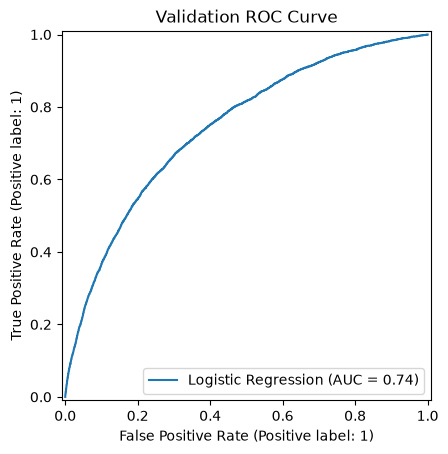

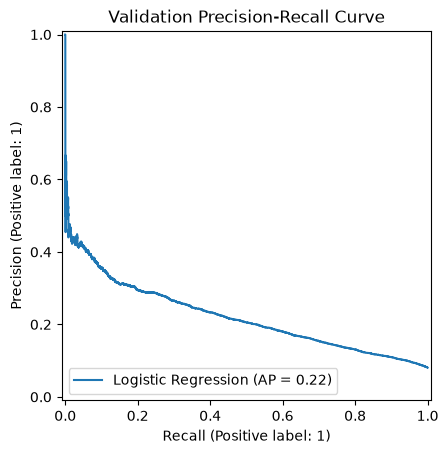

In [8]:
from sklearn.metrics import (
    RocCurveDisplay,
    PrecisionRecallDisplay
)

val_probabilities = logistic_model.predict_proba(X_val)[:, 1]

RocCurveDisplay.from_predictions(
    y_val,
    val_probabilities,
    name="Logistic Regression"
)
plt.title("Validation ROC Curve")
plt.show()

PrecisionRecallDisplay.from_predictions(
    y_val,
    val_probabilities,
    name="Logistic Regression"
)
plt.title("Validation Precision-Recall Curve")
plt.show()

In [9]:
threshold_results = []

for threshold in [0.05, 0.10, 0.15, 0.20, 0.30, 0.50]:
    predictions = (
        val_probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, predictions, labels=[0, 1]
    ).ravel()

    threshold_results.append({
        "Threshold": threshold,
        "Applicants Flagged": int(predictions.sum()),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "False Positives": int(fp),
        "False Negatives": int(fn)
    })

threshold_df = pd.DataFrame(threshold_results)
display(threshold_df.round(3))


,Threshold,Applicants Flagged,Precision,Recall,False Positives,False Negatives
0,0.05,35068,0.120,0.844,30876,773
1,0.10,16566,0.180,0.601,13583,1982
2,0.15,8365,0.234,0.395,6404,3004
3,0.20,4426,0.285,0.254,3164,3703
4,0.30,1222,0.366,0.090,775,4518
5,0.50,63,0.524,0.007,30,4932


In [10]:
import joblib

MODEL_DIR = ROOT / "models"
REPORT_DIR = ROOT / "reports"

MODEL_DIR.mkdir(exist_ok=True)
REPORT_DIR.mkdir(exist_ok=True)

joblib.dump(
    logistic_model,
    MODEL_DIR / "logistic_regression.joblib"
)

results.to_csv(
    REPORT_DIR / "day05_model_metrics.csv"
)

threshold_df.to_csv(
    REPORT_DIR / "day05_threshold_analysis.csv",
    index=False
)

print("Model and aggregate validation results saved.")

Model and aggregate validation results saved.
